# Exercise 1 (10 points)

In this exercise, we will practice how to properly format code. You are given a simple but poorly formatted Python code snippet that performs some common data science tasks (loading data, cleaning, and basic analysis). Your task is to refactor the code to improve readability, organization, and adhere to Python's PEP8 formatting guidelines.

```
import pandas as pd 
import numpy as np

data=pd.read_csv('credit_risk_dataset.csv')
# drop rows with missing values
data=data.dropna()

cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
def converting_datatypes(df, cat_cols, df_train=False):
    
    for col in cat_cols:
        df[col] = df[col].astype('category')
    
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = df['cb_person_cred_hist_length'].astype('int32') 
    
    if df_train==True:

        df['loan_status'] = df['loan_status'].astype('int8')
        
    return df
        
data = converting_datatypes(data, cat_cols, df_train=True)

X=data.drop('loan_status',axis=1)
y=data['loan_status']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

from sklearn.ensemble import HistGradientBoostingClassifier
hg=HistGradientBoostingClassifier(n_estimators=100, categorical_features='from_dtype')
hg.fit(X_train,y_train)
print('Train accuracy:',hg.score(X_train,y_train))
print('Test accuracy:',hg.score(X_test,y_test))
```

In [1]:

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split


# Load the dataset and remove missing values.
data = pd.read_csv("credit_risk_dataset.csv")
data = data.dropna()

# Identify categorical columns.
cat_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]


def converting_datatypes(df, cat_cols, df_train=False):
    """Convert columns to the appropriate data types."""
    for col in cat_cols:
        df[col] = df[col].astype("category")

    df["person_age"] = df["person_age"].astype("int32")
    df["cb_person_cred_hist_length"] = df[
        "cb_person_cred_hist_length"
    ].astype("int32")

    if df_train:
        df["loan_status"] = df["loan_status"].astype("int8")

    return df


# Convert data types.
data = converting_datatypes(data, cat_cols, df_train=True)

# Separate features and target.
X = data.drop("loan_status", axis=1)
y = data["loan_status"]

# Split the dataset into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Train the classification model.
hg = HistGradientBoostingClassifier(
    max_iter=100,
    categorical_features="from_dtype",
)
hg.fit(X_train, y_train)

# Display model accuracy.
print("Train accuracy:", hg.score(X_train, y_train))
print("Test accuracy:", hg.score(X_test, y_test))


Train accuracy: 0.9443779307592537
Test accuracy: 0.9297020484171322


# Exercise 2

In this exercise, we will practice data visualiation with the `credit_risk_dataset.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [4]:
%pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `credit_risk_dataset.csv` data file and create a data frame called `credit`.

In [3]:
credit = pd.read_csv("credit_risk_dataset.csv")

credit.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Exercise 2(c) (4 points)

Create a histogram of `person_income`. Color the distribution based on `loan_status`. Comment on the shape of the distributions.

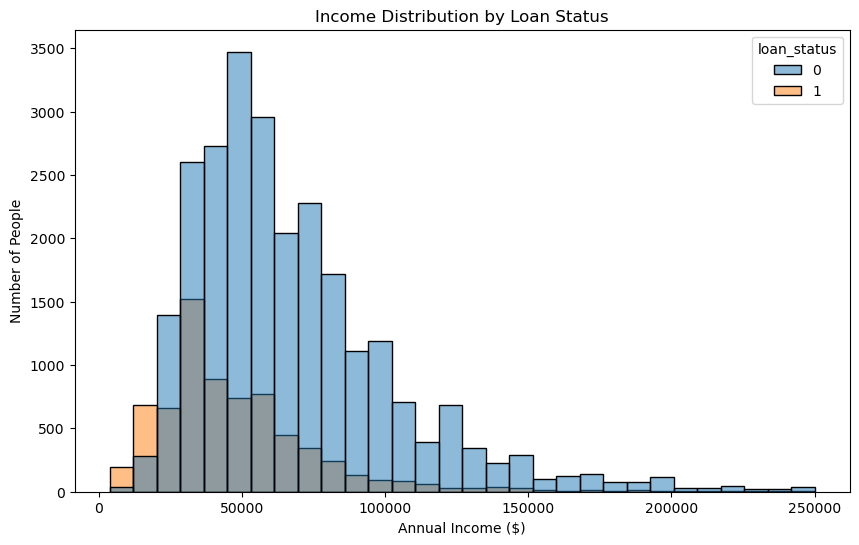

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=credit[credit["person_income"] <= 250000],
    x="person_income",
    hue="loan_status",
    bins=30,
    alpha=0.5
)

plt.title("Income Distribution by Loan Status")
plt.xlabel("Annual Income ($)")
plt.ylabel("Number of People")

plt.show()

The histogram shows that most people earn between $20,000 and $100,000 a year. Both loan status groups are right-skewed, meaning fewer people have very high incomes. People in loan status 0 generally have higher incomes, while loan status 1 is more concentrated among lower-income individuals. Overall, the graph suggests that income may be related to loan status.

### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `loan_int_rate` based on `loan_grade`. Describe the chart.

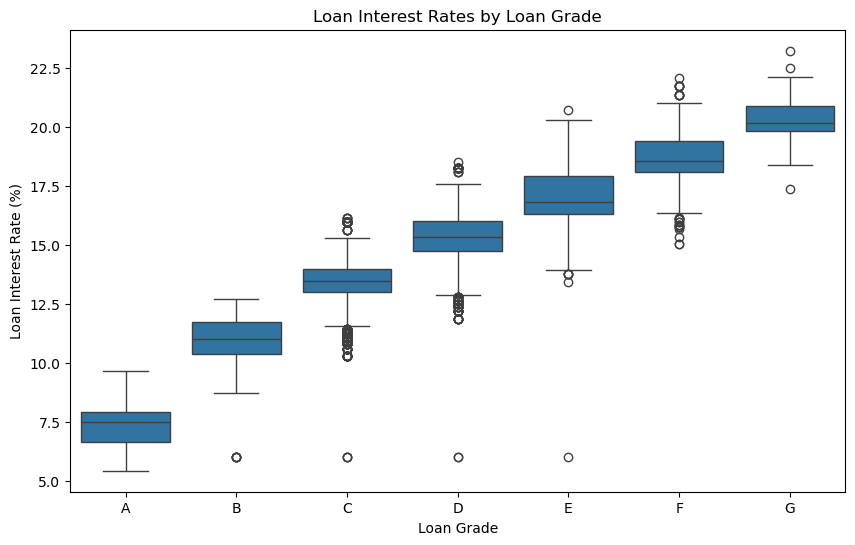

In [8]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=credit,
    x="loan_grade",
    y="loan_int_rate",
    order=["A", "B", "C", "D", "E", "F", "G"]
)

plt.title("Loan Interest Rates by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Loan Interest Rate (%)")

plt.show()

The boxplot shows that interest rates increase as loan grades move from A to G. Grade A has the lowest interest rates, around 7.5%, while Grade G has the highest, around 20%. This suggests that borrowers with lower loan grades are charged higher interest rates. There are also some outliers, but the overall pattern is clear.

### Exercise 2(e) (10 points)

Is there a realtionship between `person_home_ownership`, `loan_intent`, and `loan_status`? Create a heatmap that shows the average `loan_status` based on `person_home_ownership` and `loan_intent`. Describe the chart.

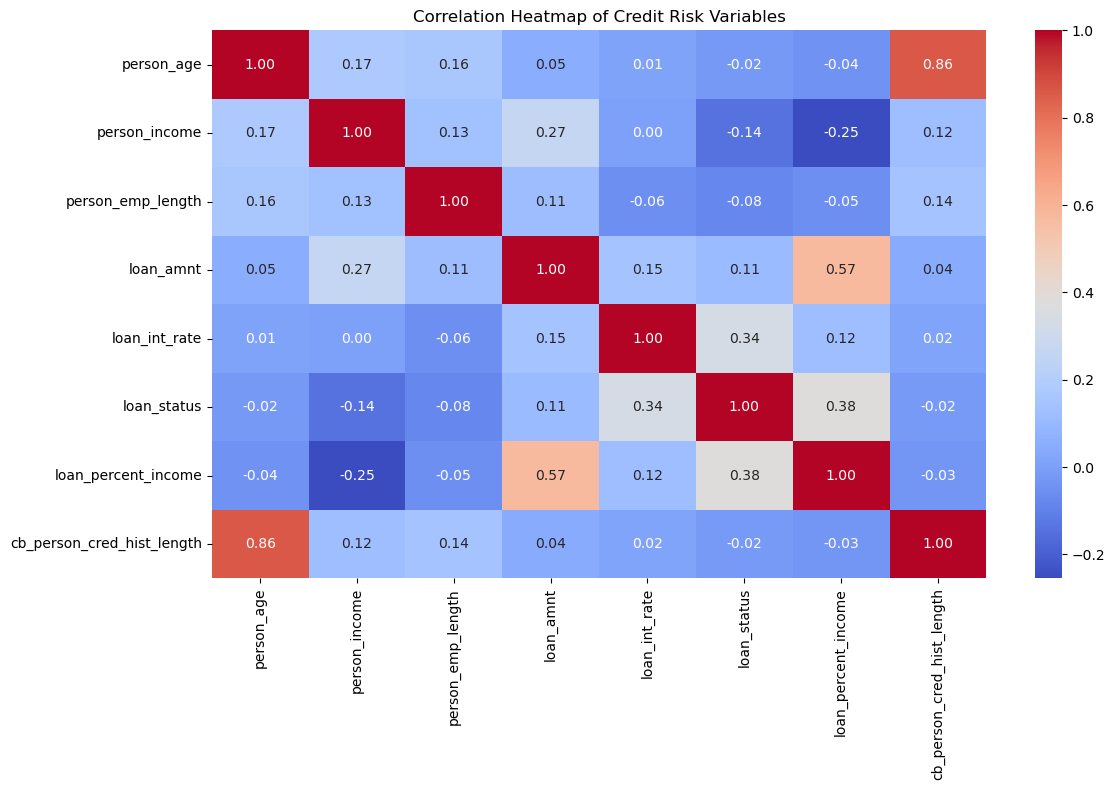

In [9]:
# Select numerical columns and calculate correlations.
numeric_data = credit.select_dtypes(include="number")
correlation = numeric_data.corr()

# Create the heatmap.
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Credit Risk Variables")
plt.tight_layout()
plt.show()

The heatmap shows how different factors in the dataset are related. The strongest relationship is between age and credit history length (0.86), meaning older people generally have longer credit histories. Loan amount and loan-to-income ratio also have a positive relationship (0.57). Loan status has a positive relationship with loan-to-income ratio (0.38) and interest rate (0.34). Income has a weak negative relationship with loan status (-0.14). Overall, the results suggest that interest rates and the amount borrowed compared to income may be important factors when looking at loan risk.

# Exercise 3 (10 points)

In this exercise, we will practice import formatting (Section 6.2 of Chapter 6).

### Exercise 3(a) (5 points)

The import block below grew organically and does not follow PEP8. Rewrite it so that:

- imports are grouped as (1) standard library, (2) third-party libraries, with a blank line between groups,
- imports are sorted alphabetically within each group (`import x` statements before `from x import y` statements),
- there is only one import per module line (for example, `import sys, os` must be split), and
- repeated imports from the same module are merged into a single line.


In [10]:
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

### Exercise 3(b) (5 points)

Name two cases where reordering imports (for example, with `isort`) is **not** behavior-preserving. How can you tell `isort` to leave a line alone?

Reordering imports can sometimes change how a Python program works.

1. Some libraries need to be imported in a specific order because one library depends on another being loaded first.

2. Some imports run setup code when they are loaded. Changing their order could affect how the program behaves.

To prevent `isort` from changing a particular import line, we can add `# isort: skip` at the end of that line.